# ETA Based Supply

## Run this example in [Colab](https://colab.research.google.com/github/SignalOceanSdk/SignalSDK/blob/master/docs/examples/jupyter/SupplyAPI/EtaBasedSupply.ipynb)

Which Aframax tankers can reach Houston in the next 10 days at 13 knots, have recently updated commercial data, and are in the spot or relet market?

## Setup
Install the Signal Ocean SDK:
```
pip install signal-ocean
```
You need your own API key with access to the Supply API, for the vessel classes that you query. Get your key here: https://apis.signalocean.com/profile

In [ ]:
!pip install signal-ocean

In [2]:
signal_ocean_api_key = ''  # Replace with your subscription key

In [3]:
from datetime import date

from signal_ocean import Connection
from signal_ocean.supply import (
    CommercialAvailabilityFilter,
    EtaCalculationBasis,
    EtaConfiguration,
    EtaConfigurationWithRestrictions,
    FromToRange,
    LiveSupplyFilter,
    MarketDeployment,
    MinMaxRange,
    Restrictions,
    SupplyAPI,
    SupplyFilter,
    VesselClass,
)

connection = Connection(signal_ocean_api_key)
api = SupplyAPI(connection)

## Filters
An ETA configuration calculates each vessel's ETA to a port. Its `id` names the ETA columns in the data frame.

- `basis_port_id`: Houston (3853).
- `speed` 13 knots and `sea_margin` 10%.
- `eta_calculation_basis`: start from the earliest open date and location.
- `eta_relative_offset`: arrive within 10 days.

In [4]:
commercial = CommercialAvailabilityFilter(
    latest_updated_date_relative_offset=FromToRange(from_=-5, to=0),
    market_deployment=[MarketDeployment.SPOT, MarketDeployment.RELET],
)
eta_settings = dict(
    id="houston",
    basis_port_id=3853,
    speed=13.0,
    sea_margin=10,
    eta_calculation_basis=EtaCalculationBasis.EARLIEST_OPEN_DATE,
    eta_relative_offset=MinMaxRange(min=0, max=10),
)

filters = SupplyFilter(
    vessel_class=VesselClass.AFRAMAX,
    commercial_availability=commercial,
    eta_configuration=[EtaConfiguration(**eta_settings)],
)

## Supply trend
On the trend, the API calculates ETAs to hub ports. A basis port that is not a hub port is replaced by the hub port of its region, and `notes` says so.

In [5]:
trend = api.get_supply_trend(date(2026, 8, 1), date(2026, 10, 31), filters=filters)
print(trend.notes)
trend_frame = trend.to_data_frame()
trend_frame.tail()

()


,supply
date,
2026-10-27,18
2026-10-28,18
2026-10-29,22
2026-10-30,19
2026-10-31,15


<Axes: title={'center': 'Aframax tankers that can reach Houston within 10 days'}, ylabel='Vessels'>

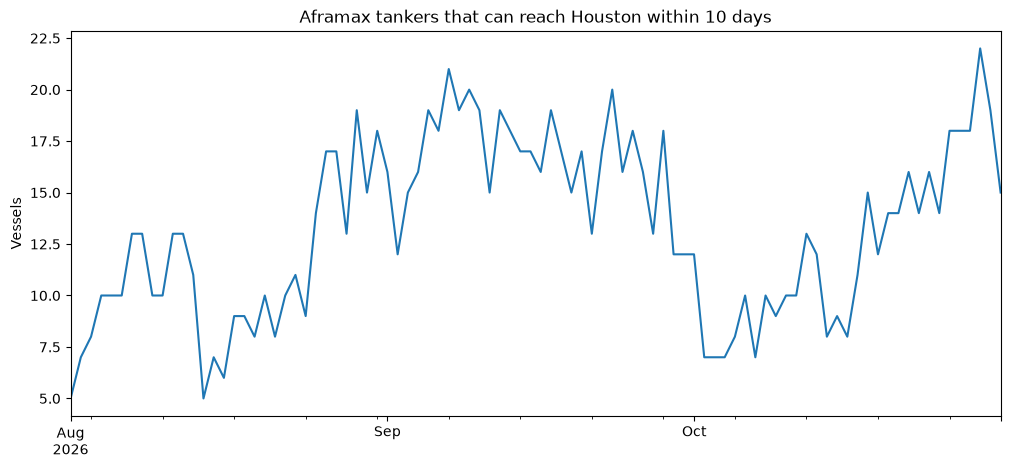

In [6]:
trend_frame.plot(y="supply", figsize=(12, 5), legend=False,
    title="Aframax tankers that can reach Houston within 10 days", ylabel="Vessels", xlabel="")

## The vessels now, by ETA

In [7]:
live_frame = api.get_live_supply(filters=filters).to_data_frame()
live_frame.sort_values("eta_houston")[
    ["imo", "open_location", "open_date_from", "eta_houston",
     "eta_distance_houston", "eta_canals_houston"]
]

,imo,open_location,open_date_from,eta_houston,eta_distance_houston,eta_canals_houston
3,9787936,US Gulf,2026-11-11 09:51:36.000+00:00,2026-11-13 04:00:00+00:00,50.30,[]
6,1071434,US Gulf,2026-11-11 09:43:06.000+00:00,2026-11-13 05:00:00+00:00,51.54,[]
0,9528043,US Gulf,2026-11-11 09:48:48.000+00:00,2026-11-13 17:00:00+00:00,65.79,[]
5,9777943,US Gulf,2026-11-11 09:40:41.000+00:00,2026-11-14 00:00:00+00:00,73.34,[]
1,1020930,US Gulf,2026-11-11 09:40:54.000+00:00,2026-11-14 09:00:00+00:00,84.27,[]
7,9518892,US Gulf,2026-11-11 09:44:49.000+00:00,2026-11-14 09:00:00+00:00,84.77,[]
8,9624067,US Gulf,2026-11-11 09:39:06.000+00:00,2026-11-14 10:00:00+00:00,85.71,[]
11,1021594,Freeport (Texas),2026-11-15 01:33:01.062+00:00,2026-11-17 16:00:00+00:00,74.08,[]
4,9683013,US Gulf,2026-11-11 09:51:06.000+00:00,2026-11-17 18:00:00+00:00,180.23,[]
10,9645401,US Gulf,2026-11-11 09:32:58.000+00:00,2026-11-19 17:00:00+00:00,236.00,[]


## Routing restrictions on live supply
On live supply, an ETA configuration can also set routing restrictions. Use `LiveSupplyFilter` and `EtaConfigurationWithRestrictions` for this. Here the route may not use the Panama Canal.

In [8]:
no_panama = LiveSupplyFilter(
    vessel_class=VesselClass.AFRAMAX,
    commercial_availability=commercial,
    eta_configuration=[
        EtaConfigurationWithRestrictions(**eta_settings, restrictions=Restrictions.PANAMA)
    ],
)
no_panama_frame = api.get_live_supply(filters=no_panama).to_data_frame()
print(f"Default routing: {len(live_frame)} vessels, without Panama: {len(no_panama_frame)} vessels")

Default routing: 12 vessels, without Panama: 12 vessels


In [9]:
connection.close()